# 05 Leave-One-Generator-Out: unseen music generator

**Research question:** What happens when a model trained on four AI music generators encounters audio from a fifth generator that was never present during training?

It does not implement `Unknown` rejection yet, instead the classifier has only four known labels and must choose one of them.

**Input:** `data/interim/split_metadata.csv` and `data/interim/muq_embeddings_full.npz`, prepared by notebooks 01–02.

**Method:** 
1. The original `train / validation / test` groups.
2. Remove the held-out generator from model fitting and known validation.
3. Evaluate known classes on the original test split and inspect forced assignments of the held-out generator's test clips. 

**Outputs:** CSVs and figures in `results/open_set/`.

## 1. Imports and paths



In [1]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


def locate_project_root():
    """Works whether Jupyter starts in the project root or notebooks/."""
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "data/interim/split_metadata.csv").is_file():
            return candidate
    raise FileNotFoundError(
        "Cannot find data/interim/split_metadata.csv. "
        "Start Jupyter from the repository, or copy the data to that path."
    )


ROOT = locate_project_root()
DATA_DIR = ROOT / "data" / "interim"
OUT_DIR = ROOT / "results" / "open_set"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Data directory:", DATA_DIR)
print("Outputs:", OUT_DIR)

Project root: d:\UCU\33333333333333333\AI\AI-vs-Original-Music-Classification
Data directory: d:\UCU\33333333333333333\AI\AI-vs-Original-Music-Classification\data\interim
Outputs: d:\UCU\33333333333333333\AI\AI-vs-Original-Music-Classification\results\open_set


## 2. Experiment settings

- **One generator out run:** `RUN_ALL_FOLDS = False` and `HELD_OUT_GENERATOR = "mustango"` tests **Mustango** only.
- **After checking the first results:** `RUN_ALL_FOLDS = True`.
- We start with Logistic Regression because it is reasonably fast locally and produces class probabilities for diagnostics.

In [9]:
RUN_ALL_FOLDS = True          # False is for testing only when just one generator out.
HELD_OUT_GENERATOR = "mustango"  # Exact label from metadata
RANDOM_STATE = 42
MODEL_C = 1.0
MODEL_MAX_ITER = 1000

META_FILE = DATA_DIR / "split_metadata.csv"
MUQ_FILE = DATA_DIR / "muq_embeddings_full.npz"

## 3. Inspect and validate the original split

Keep each `track_id` in exactly one of train, validation or test.

In [10]:
KEYS = ["track_id", "generator", "split"]
metadata = pd.read_csv(META_FILE, dtype={"track_id": str})
missing_columns = set(KEYS) - set(metadata.columns)
if missing_columns:
    raise ValueError(f"Metadata is missing required columns: {missing_columns}")

metadata[KEYS] = metadata[KEYS].astype(str)
if metadata.duplicated(KEYS).any():
    raise ValueError("Duplicate (track_id, generator, split) keys in metadata")
if metadata[KEYS].isna().any().any():
    raise ValueError("Missing values in required metadata columns")

expected_splits = {"train", "validation", "test"}
if set(metadata["split"].unique()) != expected_splits:
    raise ValueError(f"Unexpected split names: {sorted(metadata['split'].unique())}")

track_split_counts = metadata.groupby("track_id")["split"].nunique()
if not track_split_counts.eq(1).all():
    raise ValueError("Leakage: some track IDs appear in more than one split")

generators = sorted(metadata["generator"].unique().tolist())
if len(generators) != 5:
    raise ValueError(f"Expected 5 generator labels, found {generators}")

print(f"Clips: {len(metadata):,} | Unique track IDs: {metadata['track_id'].nunique():,}")
print("Generators:", generators)
display(pd.crosstab(metadata["split"], metadata["generator"]))
assert len(metadata) == 27605, "Expected full FakeMusicCaps metadata (27,605 clips)"

Clips: 27,605 | Unique track IDs: 5,521
Generators: ['MusicGen_medium', 'audioldm2', 'musicldm', 'mustango', 'stable_audio_open']


generator,MusicGen_medium,audioldm2,musicldm,mustango,stable_audio_open
split,,,,,
test,829,829,829,829,829
train,3864,3864,3864,3864,3864
validation,828,828,828,828,828


## 4. Load and align MuQ embeddings

The NPZ from notebook 02 includes `embeddings`, `track_ids`, `generators`, and `splits`.


In [4]:
if not MUQ_FILE.is_file():
    raise FileNotFoundError(f"MuQ file not found: {MUQ_FILE}")

with np.load(MUQ_FILE, allow_pickle=True) as saved:
    required = {"embeddings", "track_ids", "generators", "splits"}
    missing = required - set(saved.files)
    if missing:
        raise ValueError(f"NPZ is missing arrays: {missing}")

    embedded_keys = pd.MultiIndex.from_arrays([
        np.asarray(saved["track_ids"], dtype=str),
        np.asarray(saved["generators"], dtype=str),
        np.asarray(saved["splits"], dtype=str),
    ], names=KEYS)
    target_keys = pd.MultiIndex.from_frame(metadata[KEYS].astype(str))

    if not embedded_keys.is_unique:
        raise ValueError("Duplicate keys in MuQ embeddings")
    if len(embedded_keys) != len(target_keys):
        raise ValueError("Different row counts in NPZ and split_metadata.csv")

    positions = embedded_keys.get_indexer(target_keys)
    if (positions < 0).any() or not np.array_equal(np.sort(positions), np.arange(len(target_keys))):
        raise ValueError("MuQ embeddings and metadata contain different IDs/generator/split keys")

    X = np.asarray(saved["embeddings"][positions], dtype=np.float32)

if X.shape != (len(metadata), 1024):
    raise ValueError(f"Unexpected MuQ shape: {X.shape}; expected ({len(metadata)}, 1024)")
if not np.isfinite(X).all():
    raise ValueError("MuQ embeddings contain NaN or infinite values")

y = metadata["generator"].to_numpy(dtype=str)
split = metadata["split"].to_numpy(dtype=str)
print("Aligned MuQ features:", X.shape, X.dtype)
print("No missing keys and no track-ID leakage across splits.")

Aligned MuQ features: (27605, 1024) float32
No missing keys and no track-ID leakage across splits.


## 5. Define one Leave-One-Generator-Out fold

For example, if `held_out = mustango`:

| Partition | Included labels | Used for |
|---|---|---|
| Known train | Other four generators, `split=train` | Fit StandardScaler and Logistic Regression |
| Known validation | Other four generators, `split=validation` | Check in-domain performance; future threshold calibration |
| Known test | Other four generators, `split=test` | Evaluate four-class accuracy and Macro F1 |
| Unknown test | Mustango, `split=test` | Inspect forced predictions |

All Mustango samples, including its train and validation samples, are excluded from fitting and tuning.

In [11]:
def build_model():
    # Scaling is fitted inside the pipeline ONLY on known training clips.
    return Pipeline([
        ("scale", StandardScaler()),
        ("classifier", LogisticRegression(
            C=MODEL_C,
            max_iter=MODEL_MAX_ITER,
            solver="lbfgs",
            random_state=RANDOM_STATE,
        )),
    ])


def make_predictions_frame(mask, model, held_out, status, partition):
    frame = metadata.loc[mask, KEYS].copy().reset_index(drop=True)
    pred = model.predict(X[mask]).astype(str)
    probs = model.predict_proba(X[mask])
    frame["held_out_generator"] = held_out
    frame["partition"] = partition
    frame["true_status"] = status
    frame["predicted_generator"] = pred
    frame["max_probability"] = probs.max(axis=1)
    frame["is_correct_known"] = (
        (frame["generator"] == frame["predicted_generator"]) if status == "known" else pd.NA
    )
    return frame


def run_logo_fold(held_out):
    if held_out not in generators:
        raise ValueError(f"Unknown label {held_out!r}; choose one of {generators}")
    known_classes = sorted(g for g in generators if g != held_out)
    known = y != held_out
    unknown = y == held_out

    train_known = (split == "train") & known
    val_known = (split == "validation") & known
    test_known = (split == "test") & known
    test_unknown = (split == "test") & unknown

    if not all(mask.any() for mask in (train_known, val_known, test_known, test_unknown)):
        raise ValueError("Empty train/validation/test subset")

    assert held_out not in set(y[train_known])
    assert held_out not in set(y[val_known])
    assert set(y[train_known]) == set(known_classes)
    assert set(y[val_known]) == set(known_classes)
    assert set(y[test_known]) == set(known_classes)
    assert set(y[test_unknown]) == {held_out}

    model = build_model()
    start = time.perf_counter()
    model.fit(X[train_known], y[train_known])
    elapsed = time.perf_counter() - start

    val_frame = make_predictions_frame(val_known, model, held_out, "known", "validation")
    known_frame = make_predictions_frame(test_known, model, held_out, "known", "test")
    unknown_frame = make_predictions_frame(test_unknown, model, held_out, "unknown", "test")

    val_y = val_frame["generator"].to_numpy()
    known_y = known_frame["generator"].to_numpy()
    metrics = {
        "held_out_generator": held_out,
        "representation": "MuQ",
        "model": "Logistic Regression",
        "known_classes": ", ".join(known_classes),
        "n_train_known": int(train_known.sum()),
        "n_validation_known": int(val_known.sum()),
        "n_test_known": int(test_known.sum()),
        "n_test_unknown": int(test_unknown.sum()),
        "validation_known_macro_f1": f1_score(
            val_y, val_frame["predicted_generator"], labels=known_classes, average="macro", zero_division=0
        ),
        "test_known_accuracy": accuracy_score(known_y, known_frame["predicted_generator"]),
        "test_known_balanced_accuracy": balanced_accuracy_score(known_y, known_frame["predicted_generator"]),
        "test_known_macro_f1": f1_score(
            known_y, known_frame["predicted_generator"], labels=known_classes, average="macro", zero_division=0
        ),
        "unknown_mean_max_probability": unknown_frame["max_probability"].mean(),
        "known_mean_max_probability": known_frame["max_probability"].mean(),
        "train_seconds": elapsed,
    }
    return metrics, val_frame, known_frame, unknown_frame

## 6. Run the pilot or all five folds

*The script saves results under a different filename prefix so the pilot and full comparison do not overwrite each other*

In [12]:
if RUN_ALL_FOLDS:
    held_out_list = generators.copy()
    experiment_id = "logo_all"
else:
    if HELD_OUT_GENERATOR not in generators:
        raise ValueError(f"HELD_OUT_GENERATOR must be one of {generators}")
    held_out_list = [HELD_OUT_GENERATOR]
    experiment_id = f"logo_pilot_{HELD_OUT_GENERATOR}"

metrics_rows = []
validation_frames = []
known_test_frames = []
unknown_test_frames = []

for held_out in held_out_list:
    metrics, val_preds, known_preds, unknown_preds = run_logo_fold(held_out)
    metrics_rows.append(metrics)
    validation_frames.append(val_preds)
    known_test_frames.append(known_preds)
    unknown_test_frames.append(unknown_preds)
    print(
        f"Held out: {held_out:18s} | train known={metrics['n_train_known']:5d} "
        f"| test unknown={metrics['n_test_unknown']:3d} "
        f"| known test Macro F1={metrics['test_known_macro_f1']:.4f} "
        f"| fit={metrics['train_seconds']:.1f}s"
    )

metrics_df = pd.DataFrame(metrics_rows)
validation_predictions = pd.concat(validation_frames, ignore_index=True)
known_test_predictions = pd.concat(known_test_frames, ignore_index=True)
unknown_test_predictions = pd.concat(unknown_test_frames, ignore_index=True)

display(metrics_df.round(4))

Held out: MusicGen_medium    | train known=15456 | test unknown=829 | known test Macro F1=0.9840 | fit=2.3s
Held out: audioldm2          | train known=15456 | test unknown=829 | known test Macro F1=0.9882 | fit=1.5s
Held out: musicldm           | train known=15456 | test unknown=829 | known test Macro F1=0.9882 | fit=1.7s
Held out: mustango           | train known=15456 | test unknown=829 | known test Macro F1=0.9879 | fit=2.1s
Held out: stable_audio_open  | train known=15456 | test unknown=829 | known test Macro F1=0.9837 | fit=2.1s


,held_out_generator,representation,model,known_classes,n_train_known,n_validation_known,n_test_known,n_test_unknown,validation_known_macro_f1,test_known_accuracy,test_known_balanced_accuracy,test_known_macro_f1,unknown_mean_max_probability,known_mean_max_probability,train_seconds
0,MusicGen_medium,MuQ,Logistic Regression,"audioldm2, musicldm, mustango, stable_audio_open",15456,3312,3316,829,0.9819,0.9840,0.9840,0.9840,0.9179,0.9939,2.2641
1,audioldm2,MuQ,Logistic Regression,"MusicGen_medium, musicldm, mustango, stable_au...",15456,3312,3316,829,0.9849,0.9882,0.9882,0.9882,0.8583,0.9948,1.4866
2,musicldm,MuQ,Logistic Regression,"MusicGen_medium, audioldm2, mustango, stable_a...",15456,3312,3316,829,0.9858,0.9882,0.9882,0.9882,0.8909,0.9949,1.6940
3,mustango,MuQ,Logistic Regression,"MusicGen_medium, audioldm2, musicldm, stable_a...",15456,3312,3316,829,0.9873,0.9879,0.9879,0.9879,0.8873,0.9926,2.0531
4,stable_audio_open,MuQ,Logistic Regression,"MusicGen_medium, audioldm2, musicldm, mustango",15456,3312,3316,829,0.9777,0.9837,0.9837,0.9837,0.9046,0.9936,2.1408


**Here it is notisable future problem that model not just predict well music generated by one of known classes with high probabily but also with this hight probabilyty model predict for unknown class too.**

## 7. Inspect the unknown generator's forced assignments

The model is forced to select one of the four known classes by probabilities and those probabilities are only diagnostic here.

In [13]:
assignment_counts = pd.crosstab(
    unknown_test_predictions["held_out_generator"],
    unknown_test_predictions["predicted_generator"],
)
assignment_percent = assignment_counts.div(assignment_counts.sum(axis=1), axis=0) * 100

print("Predicted known classes for the held-out generator (counts):")
display(assignment_counts)
print("Same table as a percentage of each held-out generator:")
display(assignment_percent.round(2))

selected_fold = HELD_OUT_GENERATOR if HELD_OUT_GENERATOR in held_out_list else held_out_list[0]
selected_unknown = unknown_test_predictions[
    unknown_test_predictions["held_out_generator"] == selected_fold
]
selected_known = known_test_predictions[
    known_test_predictions["held_out_generator"] == selected_fold
]

print(f"Example forced assignments for held out '{selected_fold}':")
display(selected_unknown[KEYS + ["predicted_generator", "max_probability"]].head(12))

Predicted known classes for the held-out generator (counts):


predicted_generator,MusicGen_medium,audioldm2,musicldm,mustango,stable_audio_open
held_out_generator,,,,,
MusicGen_medium,0,341,316,26,146
audioldm2,244,0,210,300,75
musicldm,178,299,0,309,43
mustango,6,315,426,0,82
stable_audio_open,253,344,182,50,0


Same table as a percentage of each held-out generator:


predicted_generator,MusicGen_medium,audioldm2,musicldm,mustango,stable_audio_open
held_out_generator,,,,,
MusicGen_medium,0.00,41.13,38.12,3.14,17.61
audioldm2,29.43,0.00,25.33,36.19,9.05
musicldm,21.47,36.07,0.00,37.27,5.19
mustango,0.72,38.00,51.39,0.00,9.89
stable_audio_open,30.52,41.50,21.95,6.03,0.00


Example forced assignments for held out 'mustango':


,track_id,generator,split,predicted_generator,max_probability
2487,-4NLarMj4xU,mustango,test,musicldm,0.999909
2488,-6pcgdLfb_A,mustango,test,audioldm2,0.494390
2489,-7wUQP6G5EQ,mustango,test,audioldm2,0.774776
2490,-DeAdhYKbGE,mustango,test,musicldm,0.978888
2491,-FEPOSP7ay0,mustango,test,audioldm2,0.995678
2492,-SWaCArvQug,mustango,test,stable_audio_open,0.527717
2493,-f1DNyngKVY,mustango,test,stable_audio_open,0.730629
2494,-lPXTBXa0tE,mustango,test,audioldm2,0.966997
2495,-m5ZlWziIeA,mustango,test,musicldm,0.546358
2496,-nlkWWphiaM,mustango,test,audioldm2,0.982934


## 8. Visualize known-class performance and forced unknown assignments

1. Figure 1: which known generators absorb each unknown generator?
2. Figure 2: illustrative confidence distributions, using ONE selected Leave-One-Generator-Out fold.
3. Figure 3: known-only confusion matrix for the same selected fold.


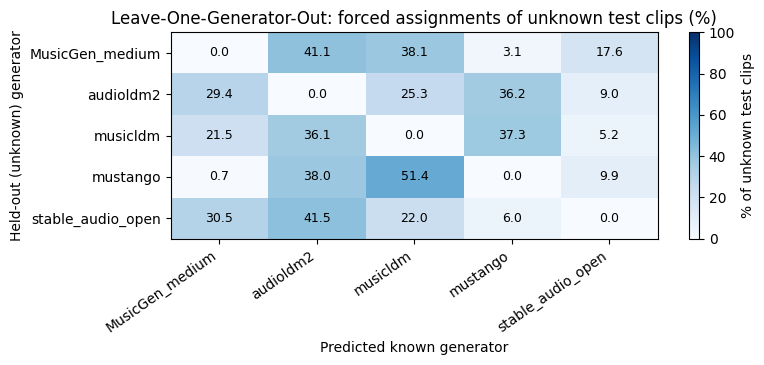

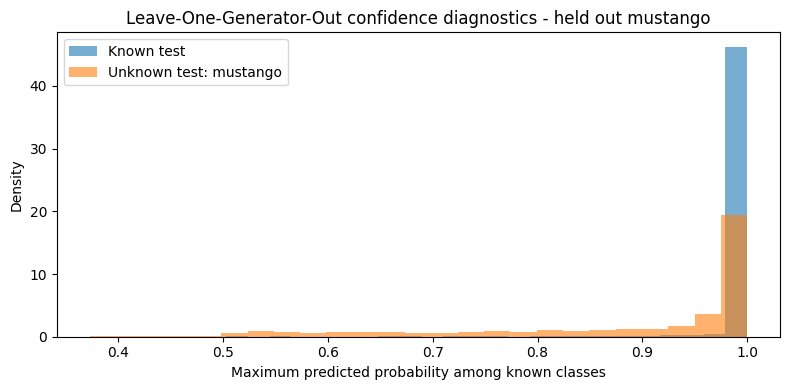

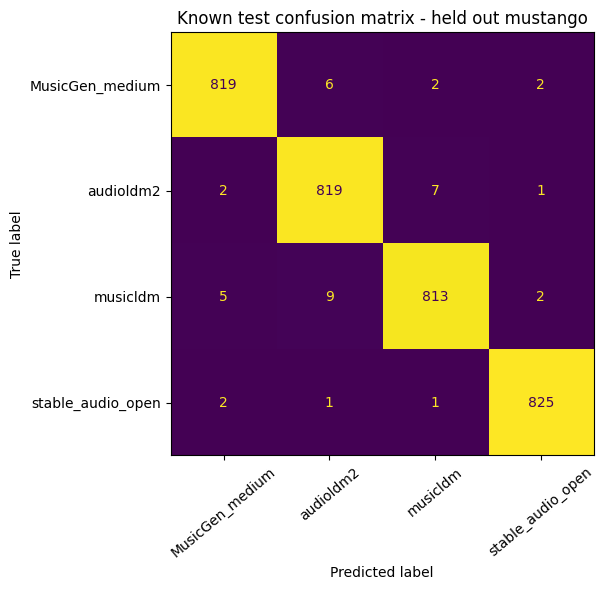

In [18]:
# Figure 1: which known generators absorb each unknown generator?
fig, ax = plt.subplots(figsize=(max(8, len(generators) * 1.25), max(3.5, len(held_out_list) * .75)))
plot_df = assignment_percent.reindex(columns=generators, fill_value=0)
im = ax.imshow(plot_df.to_numpy(), cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(np.arange(len(plot_df.columns)), plot_df.columns, rotation=35, ha="right")
ax.set_yticks(np.arange(len(plot_df.index)), plot_df.index)
ax.set_xlabel("Predicted known generator")
ax.set_ylabel("Held-out (unknown) generator")
ax.set_title("Leave-One-Generator-Out: forced assignments of unknown test clips (%)")
for r in range(len(plot_df.index)):
    for c in range(len(plot_df.columns)):
        val = plot_df.iloc[r, c]
        ax.text(c, r, f"{val:.1f}", ha="center", va="center", color="white" if val > 55 else "black", fontsize=9)
fig.colorbar(im, ax=ax, label="% of unknown test clips")
fig.tight_layout()
fig.savefig(OUT_DIR / f"{experiment_id}_unknown_assignments.png", dpi=180)
plt.show()

# Figure 2: illustrative confidence distributions, using ONE selected LOGO fold.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(selected_known["max_probability"], bins=25, alpha=0.6, density=True, label="Known test")
ax.hist(selected_unknown["max_probability"], bins=25, alpha=0.6, density=True, label=f"Unknown test: {selected_fold}")
ax.set_xlabel("Maximum predicted probability among known classes")
ax.set_ylabel("Density")
ax.set_title(f"Leave-One-Generator-Out confidence diagnostics - held out {selected_fold}")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / f"{experiment_id}_confidence_diagnostic.png", dpi=180)
plt.show()

# Figure 3: known-only confusion matrix for the same selected fold.
known_classes = sorted(set(generators) - {selected_fold})
cm = confusion_matrix(
    selected_known["generator"],
    selected_known["predicted_generator"],
    labels=known_classes,
)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=known_classes).plot(ax=ax, colorbar=False, xticks_rotation=40)
ax.set_title(f"Known test confusion matrix - held out {selected_fold}")
fig.tight_layout()
fig.savefig(OUT_DIR / f"{experiment_id}_known_confusion.png", dpi=180)
plt.show()

## 9. Save results


In [19]:
outputs = {
    "metrics": metrics_df,
    "validation_predictions": validation_predictions,
    "known_test_predictions": known_test_predictions,
    "unknown_test_predictions": unknown_test_predictions,
    "unknown_assignment_counts": assignment_counts.reset_index(),
    "unknown_assignment_percent": assignment_percent.reset_index(),
}
for label, frame in outputs.items():
    dest = OUT_DIR / f"{experiment_id}_{label}.csv"
    frame.to_csv(dest, index=False)
    print("Saved", dest.relative_to(ROOT))

run_config = {
    "experiment_id": experiment_id,
    "task": "Leave-one-generator-out forced-choice diagnostic (NOT unknown detection)",
    "representation": "MuQ 1024-dimensional frozen embedding",
    "classifier": "StandardScaler -> LogisticRegression",
    "logreg_C": MODEL_C,
    "logreg_max_iter": MODEL_MAX_ITER,
    "random_state": RANDOM_STATE,
    "held_out_generators": held_out_list,
    "source_metadata": str(META_FILE.relative_to(ROOT)),
    "source_embeddings": str(MUQ_FILE.relative_to(ROOT)),
    "split_policy": "reuse original group-aware split; no train/validation samples of held-out generator",
}
config_path = OUT_DIR / f"{experiment_id}_config.json"
config_path.write_text(json.dumps(run_config, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved", config_path.relative_to(ROOT))

Saved results\open_set\logo_all_metrics.csv
Saved results\open_set\logo_all_validation_predictions.csv
Saved results\open_set\logo_all_known_test_predictions.csv
Saved results\open_set\logo_all_unknown_test_predictions.csv
Saved results\open_set\logo_all_unknown_assignment_counts.csv
Saved results\open_set\logo_all_unknown_assignment_percent.csv
Saved results\open_set\logo_all_config.json


## 10. Conclusions

We evaluated five **MuQ + Logistic Regression** models, in each fold, one music generator was entirely excluded from training and validation.

**Results on the four known generators:** the known-test Macro F1 ranges from 0.9837-0.9882, so the classifier can still distinguish the four known generators reliably.

**Forced classification of an unseen generator:** the mean maximum predicted probability is **0.8583–0.9179** across the five held-out generators, even though none of them were seen during training. There is a difference in averages, but the score distributions can overlap: mean confidence alone cannot tell us whether a fixed rejection threshold will work.


----------

# 06b Unknown Generator Detection: benchmark across representations

**Research question:** Can we flag clips from a generator unseen in training as `Unknown` rather than force a prediction among four known generators? Which audio representation works best for this task?

This follows `06-unseen-generator.ipynb` and evaluates the five Leave-One-Generator-Out folds using the existing FakeMusicCaps split. Сompare four audio representations: Handcrafted (36), CLAP (512), MERT (768) and MuQ (1024).

**Method:**
1. Hold out one entire generator, with no examples from that generator in training or threshold calibration.
2. Fit a known-generator classifier on the original `train` partition (four known classes).
3. Choose the rejection threshold solely from known `validation` clips, targeting 95% known acceptance.
4. Evaluate known test + held-out unknown test using AUROC, Unknown Recall, Known False Rejection Rate, and open-set Macro F1.
5. Repeat over all five generators and compare representations and classifiers.

Two detector aproaches:
- **Model uncertainty:** maximum predicted probability (Logistic Regression / k-NN when available); optionally SVM decision-score margin if probabilities are not exposed.
- **Cosine distance to the nearest class centroid:** fixed representation-based detector; the Logistic Regression classifier provides labels for accepted known clips.



## 1. Setup

**Input files in `data/interim/`:**
- `split_metadata.csv`
- `handcrafted_features_full.csv`
- `muq_embeddings_full.npz`, `mert_embeddings_full.npz`, `clap_embeddings_full.npz`


In [31]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (roc_auc_score, f1_score, accuracy_score,
                             balanced_accuracy_score)
from sklearn.preprocessing import StandardScaler, normalize

RUN_EXTENDED = True  # False: 4×LogReg; True: also SVM and k-NN (all 4 representations)
REPRESENTATION_ORDER = ["MuQ", "Handcrafted", "MERT", "CLAP"]
TARGET_KNOWN_ACCEPTANCE = 0.95
RANDOM_STATE = 42
SAVE_ALL_PREDICTIONS = True


def find_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'data/interim/split_metadata.csv').is_file():
            return candidate
    raise FileNotFoundError('Start Jupyter in the project or notebooks/ folder; '
                            'data/interim/split_metadata.csv was not found')

ROOT = find_root()
DATA_DIR = ROOT / 'data' / 'interim'
OUT_DIR = ROOT / 'results' / 'open_set' / 'unknown_detection'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Existing project model factories: same family / configuration as notebook 03.
import sys
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from ai_music_origin.config import load_config
from ai_music_origin.models import build_logistic_regression, build_svm, build_knn
config = load_config(ROOT / 'config' / 'default.yaml')

CLASSIFIERS = ['Logistic Regression']
if RUN_EXTENDED:
    CLASSIFIERS += ['SVM', 'k-NN']
MODEL_FACTORIES = {
    'Logistic Regression': build_logistic_regression,
    'SVM': build_svm,
    'k-NN': build_knn,
}

print('Project:', ROOT)
print('Representations:', REPRESENTATION_ORDER)
print('Classifiers:', CLASSIFIERS)
print(f'Known acceptance target (validation): {TARGET_KNOWN_ACCEPTANCE:.0%}')

Project: d:\UCU\33333333333333333\AI\AI-vs-Original-Music-Classification
Representations: ['MuQ', 'Handcrafted', 'MERT', 'CLAP']
Classifiers: ['Logistic Regression', 'SVM', 'k-NN']
Known acceptance target (validation): 95%


## 2. Verify the metadata and original group-aware split

All generators share the same MusicCaps prompts (`track_id`). The held-out generator has **0 examples** in model fitting, scaler fitting, centroid fitting and threshold calibration.

In [32]:
KEYS = ['track_id', 'generator', 'split']
meta = pd.read_csv(DATA_DIR / 'split_metadata.csv', dtype={'track_id': str})
if not set(KEYS).issubset(meta.columns):
    raise ValueError(f'Missing metadata columns: {set(KEYS) - set(meta.columns)}')
if meta[KEYS].isna().any().any():
    raise ValueError('Missing metadata key values')
if meta.duplicated(KEYS).any():
    raise ValueError('Duplicate (track_id, generator, split)')
if set(meta['split'].unique()) != {'train', 'validation', 'test'}:
    raise ValueError('Unexpected splits')
if not meta.groupby('track_id')['split'].nunique().eq(1).all():
    raise ValueError('Prompt leakage: a track_id occurs in multiple splits')

labels = meta['generator'].astype(str).to_numpy()
splits = meta['split'].astype(str).to_numpy()
generators = sorted(meta['generator'].astype(str).unique().tolist())
if len(generators) != 5:
    raise ValueError(f'Expected 5 generator labels, got {generators}')
if len(meta) != 27605:
    raise ValueError(f'Expected full FakeMusicCaps (27605 clips), got {len(meta)}')
display(pd.crosstab(meta['split'], meta['generator']))
print('Clips:', len(meta), '| Generators:', generators)

FOLD_MASKS = {}
for held_out in generators:
    is_known = labels != held_out
    mask = {
        'train': (splits == 'train') & is_known,
        'val': (splits == 'validation') & is_known,
        'known_test': (splits == 'test') & is_known,
        'unknown_test': (splits == 'test') & ~is_known,
    }
    assert [int(mask[x].sum()) for x in ['train', 'val', 'known_test', 'unknown_test']] == [15456, 3312, 3316, 829]
    assert held_out not in set(labels[mask['train']])
    assert held_out not in set(labels[mask['val']])
    FOLD_MASKS[held_out] = mask
print('Validated all 5 held-out-generator partitions.')

generator,MusicGen_medium,audioldm2,musicldm,mustango,stable_audio_open
split,,,,,
test,829,829,829,829,829
train,3864,3864,3864,3864,3864
validation,828,828,828,828,828


Clips: 27605 | Generators: ['MusicGen_medium', 'audioldm2', 'musicldm', 'mustango', 'stable_audio_open']
Validated all 5 held-out-generator partitions.


## 3. Load and align each representation

To limit RAM consumption, we load one representation at a time. Embeddings are aligned to metadata via `(track_id, generator, split)`.


In [33]:
def align_matrix(vectors, ids, gens, saved_splits, source):
    stored = pd.MultiIndex.from_arrays([
        np.asarray(ids, dtype=str), np.asarray(gens, dtype=str), np.asarray(saved_splits, dtype=str)
    ], names=KEYS)
    expected = pd.MultiIndex.from_frame(meta[KEYS].astype(str))
    if not stored.is_unique or len(stored) != len(expected):
        raise ValueError(f'{source}: duplicate/missing keys or wrong number of rows')
    indices = stored.get_indexer(expected)
    if (indices < 0).any() or not np.array_equal(np.sort(indices), np.arange(len(meta))):
        raise ValueError(f'{source}: keys do not match metadata')
    X = np.asarray(vectors[indices], dtype=np.float32)
    if X.ndim != 2 or not np.isfinite(X).all():
        raise ValueError(f'{source}: invalid data values')
    return X


def load_representation(name):
    if name == 'Handcrafted':
        file = DATA_DIR / 'handcrafted_features_full.csv'
        hc = pd.read_csv(file, dtype={'track_id': str})
        cols = [c for c in hc.columns if c not in KEYS]
        if len(cols) != 36 or not all(pd.api.types.is_numeric_dtype(hc[c]) for c in cols):
            raise ValueError(f'Expected 36 numeric handcrafted features; got {len(cols)}')
        return align_matrix(hc[cols].to_numpy(dtype=np.float32),
                            hc['track_id'], hc['generator'], hc['split'], file.name)
    files = {'MuQ': 'muq_embeddings_full.npz',
             'MERT': 'mert_embeddings_full.npz',
             'CLAP': 'clap_embeddings_full.npz'}
    file = DATA_DIR / files[name]
    with np.load(file, allow_pickle=True) as archive:  # use only your trusted local files
        needed = {'embeddings', 'track_ids', 'generators', 'splits'}
        if not needed.issubset(archive.files):
            raise ValueError(f'{file.name} missing arrays {needed - set(archive.files)}')
        return align_matrix(archive['embeddings'], archive['track_ids'],
                            archive['generators'], archive['splits'], file.name)

# Preview dimensions without keeping all matrices in RAM.
for rep in REPRESENTATION_ORDER:
    path = DATA_DIR / ('handcrafted_features_full.csv' if rep == 'Handcrafted' else rep.lower() + '_embeddings_full.npz')
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}')
print('All required representation files exist.')

All required representation files exist.


## 4. Unknown rejection methods

We define a novelty score where larger means more likely Unknown.

- `1 − max(predict_proba)` - maximum-probability rejection for models exposing probabilities.
- `negative_top2_margin` - optional SVM diagnostic where a smaller gap between the largest two OvR decision scores indicates uncertainty. 
- `cosine_to_centroid` — distance to the nearest training class centroid. StandardScaler is fitted on known train only; then each scaled vector is L2-normalized. Used with Logistic Regression known-class predictions, once per representation/fold.



In [34]:
def novelty_from_classifier(estimator, X, n_classes):
    # Prefer class probabilities. SVM may not expose predict_proba (notably a normal SVC).
    if hasattr(estimator, 'predict_proba'):
        try:
            proba = np.asarray(estimator.predict_proba(X), dtype=np.float64)
            if proba.ndim == 2 and proba.shape[1] == n_classes:
                return 'one_minus_max_probability', 1.0 - np.max(proba, axis=1)
        except (AttributeError, NotImplementedError):
            pass
    if hasattr(estimator, 'decision_function'):
        d = np.asarray(estimator.decision_function(X), dtype=np.float64)
        if d.ndim == 2 and d.shape[1] == n_classes:
            # Heuristic: relative OvR rank/score margin. Not calibrated confidence.
            top2 = np.partition(d, kth=-2, axis=1)[:, -2:]
            return 'negative_top2_decision_margin', -(top2.max(axis=1) - top2.min(axis=1))
    return None, None


def centroid_novelty(X_train, y_train, arrays):
    scaler = StandardScaler()
    A_train = normalize(scaler.fit_transform(X_train))
    known_classes = sorted(np.unique(y_train).tolist())
    centers = np.stack([A_train[y_train == c].mean(axis=0) for c in known_classes])
    centers = normalize(centers)
    out = []
    for X_part in arrays:
        A_part = normalize(scaler.transform(X_part))
        similarity = A_part @ centers.T
        out.append(1.0 - similarity.max(axis=1))
    return out


def choose_threshold(validation_novelty, target_acceptance=0.95):
    scores = np.asarray(validation_novelty, dtype=float)
    if not np.isfinite(scores).all() or len(scores) == 0:
        raise ValueError('Invalid validation novelty')
    # Strict > keeps examples tied with the threshold as Known.
    return float(np.quantile(scores, target_acceptance))


def evaluate_detector(held_out, rep, classifier, detector, threshold,
                      known_pred, unknown_pred, val_scores, known_scores,
                      unknown_scores, fit_seconds):
    m = FOLD_MASKS[held_out]
    true_known = labels[m['known_test']]
    y_true = np.concatenate([true_known.astype(object),
                             np.full(m['unknown_test'].sum(), 'Unknown', dtype=object)])
    known_scores = np.asarray(known_scores, dtype=float)
    unknown_scores = np.asarray(unknown_scores, dtype=float)
    novelty = np.concatenate([known_scores, unknown_scores])
    predicted = np.concatenate([known_pred, unknown_pred]).astype(object)
    predicted[novelty > threshold] = 'Unknown'
    cls = sorted(set(generators) - {held_out}) + ['Unknown']
    unknown_true = np.r_[np.zeros(len(known_scores), dtype=int),
                         np.ones(len(unknown_scores), dtype=int)]
    if not np.isfinite(novelty).all():
        raise ValueError(f'Non-finite novelty scores for {rep} / {detector}')
    result = {
        'representation': rep,
        'classifier': classifier,
        'detector': detector,
        'held_out_generator': held_out,
        'threshold': threshold,
        'validation_known_acceptance': float(np.mean(np.asarray(val_scores) <= threshold)),
        'known_false_rejection_rate': float(np.mean(known_scores > threshold)),
        'unknown_recall': float(np.mean(unknown_scores > threshold)),
        'known_forced_macro_f1': f1_score(true_known, known_pred, labels=cls[:-1], average='macro', zero_division=0),
        'known_accepted_correct_fraction': float(np.mean((np.asarray(known_pred) == true_known) & (known_scores <= threshold))),
        'open_set_macro_f1': f1_score(y_true, predicted, labels=cls, average='macro', zero_division=0),
        'open_set_balanced_accuracy': balanced_accuracy_score(y_true, predicted),
        'known_unknown_auroc': roc_auc_score(unknown_true, novelty),
        'n_train_known': int(m['train'].sum()),
        'n_val_known': int(m['val'].sum()),
        'n_test_known': int(m['known_test'].sum()),
        'n_test_unknown': int(m['unknown_test'].sum()),
        'fit_seconds': float(fit_seconds),
    }
    if not SAVE_ALL_PREDICTIONS:
        return result, None
    test_mask = m['known_test'] | m['unknown_test']
    pred_df = meta.loc[test_mask, KEYS].copy().reset_index(drop=True)
    # test_mask preserves original dataframe row order; form arrays indexed the same way.
    all_scores = np.full(len(meta), np.nan, dtype=float)
    all_preds = np.full(len(meta), '', dtype=object)
    all_scores[m['known_test']] = known_scores
    all_scores[m['unknown_test']] = unknown_scores
    all_preds[m['known_test']] = known_pred
    all_preds[m['unknown_test']] = unknown_pred
    pred_df['novelty_score'] = all_scores[test_mask]
    pred_df['forced_prediction'] = all_preds[test_mask]
    pred_df['predicted_open_set'] = np.where(pred_df['novelty_score'].to_numpy() > threshold, 'Unknown', pred_df['forced_prediction'])
    pred_df['true_open_set'] = np.where(pred_df['generator'] == held_out, 'Unknown', pred_df['generator'])
    pred_df['is_unknown'] = pred_df['generator'] == held_out
    pred_df['held_out_generator'] = held_out
    pred_df['representation'] = rep
    pred_df['classifier'] = classifier
    pred_df['detector'] = detector
    pred_df['threshold'] = threshold
    return result, pred_df

## 5. Run all five Leave-One-Generator-Out folds folds for each representation

The "FAST" run trains 20 Logistic Regression models (four representations × five folds). Extended mode adds 40 more classifier fits (SVM and k-NN); on a CPU it may take longer. To avoid memory spikes, representations are loaded one after another. The code reports each completed fold.

In [35]:
results_rows = []
all_prediction_frames = []
diagnostic = None

for rep in REPRESENTATION_ORDER:
    print(f'\n===== {rep} =====')
    X = load_representation(rep)
    print('Loaded', X.shape, X.dtype)
    for held_out in generators:
        m = FOLD_MASKS[held_out]
        X_tr, X_val = X[m['train']], X[m['val']]
        X_kt, X_ut = X[m['known_test']], X[m['unknown_test']]
        y_tr = labels[m['train']]
        known_classes = sorted(np.unique(y_tr).tolist())
        if held_out in known_classes:
            raise AssertionError('Held-out generator leaked into training')
        # One feature-space centroid detector per representation/fold.
        centroid_val, centroid_known, centroid_unknown = centroid_novelty(
            X_tr, y_tr, [X_val, X_kt, X_ut]
        )
        for clf in CLASSIFIERS:
            estimator = MODEL_FACTORIES[clf](config)
            tic = time.perf_counter()
            estimator.fit(X_tr, y_tr)
            elapsed = time.perf_counter() - tic
            val_pred = estimator.predict(X_val).astype(str)
            known_pred = estimator.predict(X_kt).astype(str)
            unknown_pred = estimator.predict(X_ut).astype(str)
            if set(np.unique(unknown_pred)) - set(known_classes):
                raise AssertionError('Unknown predictions include a class not trained')
            val_kind, val_scores = novelty_from_classifier(estimator, X_val, len(known_classes))
            known_kind, known_scores = novelty_from_classifier(estimator, X_kt, len(known_classes))
            unknown_kind, unknown_scores = novelty_from_classifier(estimator, X_ut, len(known_classes))
            if val_kind is not None and val_kind == known_kind == unknown_kind:
                threshold = choose_threshold(val_scores, TARGET_KNOWN_ACCEPTANCE)
                row, preds = evaluate_detector(
                    held_out, rep, clf, val_kind, threshold,
                    known_pred, unknown_pred, val_scores, known_scores,
                    unknown_scores, elapsed
                )
                results_rows.append(row)
                if preds is not None:
                    all_prediction_frames.append(preds)
                if rep == 'MuQ' and held_out == 'mustango' and clf == 'Logistic Regression':
                    diagnostic = {'known': known_scores, 'unknown': unknown_scores,
                                  'threshold': threshold, 'detector': val_kind}
            else:
                print('  No usable class-score detector:', rep, clf)
            # Centroid detector only once, paired with LR classification for accepted clips.
            if clf == 'Logistic Regression':
                threshold = choose_threshold(centroid_val, TARGET_KNOWN_ACCEPTANCE)
                row, preds = evaluate_detector(
                    held_out, rep, clf, 'cosine_to_nearest_centroid', threshold,
                    known_pred, unknown_pred, centroid_val,
                    centroid_known, centroid_unknown, elapsed
                )
                results_rows.append(row)
                if preds is not None:
                    all_prediction_frames.append(preds)
            print(f"  {held_out:18s} | {clf:19s} | fit {elapsed:6.1f}s | "
                  f"known forced F1={f1_score(labels[m['known_test']], known_pred, average='macro'):.4f}")
    del X

results = pd.DataFrame(results_rows)
if results.empty:
    raise RuntimeError('No detector results were generated')
print('\nCompleted detector runs:', len(results))
display(results[['representation', 'classifier', 'detector', 'held_out_generator',
                 'known_unknown_auroc', 'unknown_recall',
                 'known_false_rejection_rate', 'open_set_macro_f1']].round(4))


===== MuQ =====
Loaded (27605, 1024) float32
  MusicGen_medium    | Logistic Regression | fit    1.8s | known forced F1=0.9840
  MusicGen_medium    | SVM                 | fit   34.7s | known forced F1=0.9900
  MusicGen_medium    | k-NN                | fit    0.5s | known forced F1=0.9349
  audioldm2          | Logistic Regression | fit    1.8s | known forced F1=0.9882
  audioldm2          | SVM                 | fit   94.8s | known forced F1=0.9934
  audioldm2          | k-NN                | fit    0.5s | known forced F1=0.9332
  musicldm           | Logistic Regression | fit    2.2s | known forced F1=0.9882
  musicldm           | SVM                 | fit   52.9s | known forced F1=0.9934
  musicldm           | k-NN                | fit    0.4s | known forced F1=0.9365
  mustango           | Logistic Regression | fit    2.1s | known forced F1=0.9879
  mustango           | SVM                 | fit   79.5s | known forced F1=0.9922
  mustango           | k-NN                | fit    

,representation,classifier,detector,held_out_generator,known_unknown_auroc,unknown_recall,known_false_rejection_rate,open_set_macro_f1
0,MuQ,Logistic Regression,one_minus_max_probability,MusicGen_medium,0.8991,0.4729,0.0504,0.8421
1,MuQ,Logistic Regression,cosine_to_nearest_centroid,MusicGen_medium,0.8096,0.2388,0.0561,0.7657
2,MuQ,SVM,negative_top2_decision_margin,MusicGen_medium,0.8401,0.3800,0.0470,0.8196
3,MuQ,k-NN,one_minus_max_probability,MusicGen_medium,0.7866,0.1568,0.0199,0.7322
4,MuQ,Logistic Regression,one_minus_max_probability,audioldm2,0.9556,0.7587,0.0483,0.9112
...,...,...,...,...,...,...,...,...
75,CLAP,k-NN,one_minus_max_probability,mustango,0.6836,0.1230,0.0338,0.6578
76,CLAP,Logistic Regression,one_minus_max_probability,stable_audio_open,0.6138,0.1037,0.0525,0.6650
77,CLAP,Logistic Regression,cosine_to_nearest_centroid,stable_audio_open,0.6556,0.1496,0.0522,0.6662
78,CLAP,SVM,negative_top2_decision_margin,stable_audio_open,0.5425,0.1074,0.0561,0.6753


## 6. Compare representations and detectors (averages over five folds)

**Interpretation:** 
- high AUROC means the novelty scores tend to place unseen-generator test clips above known clips. 
- High Unknown Recall is desirable only when Known False Rejection Rate is acceptably low. 
- Open-set Macro F1 evaluates five labels: four known + `Unknown`.


In [36]:
group_cols = ['representation', 'classifier', 'detector']
comparison = results.groupby(group_cols, as_index=False).agg(
    folds=('held_out_generator', 'nunique'),
    auroc_mean=('known_unknown_auroc', 'mean'),
    auroc_std=('known_unknown_auroc', 'std'),
    unknown_recall_mean=('unknown_recall', 'mean'),
    unknown_recall_std=('unknown_recall', 'std'),
    known_frr_mean=('known_false_rejection_rate', 'mean'),
    known_frr_std=('known_false_rejection_rate', 'std'),
    open_macro_f1_mean=('open_set_macro_f1', 'mean'),
    open_macro_f1_std=('open_set_macro_f1', 'std'),
    known_forced_f1_mean=('known_forced_macro_f1', 'mean'),
    val_known_acceptance_mean=('validation_known_acceptance', 'mean'),
)
comparison = comparison.sort_values(
    ['auroc_mean', 'open_macro_f1_mean'], ascending=[False, False]
).reset_index(drop=True)
assert (comparison['folds'] == 5).all(), 'Incomplete 5-fold benchmark'
display(comparison.round(4))

# Interpretation-friendly view: which generator is hardest to flag in each method?
per_generator = results.sort_values(['representation','classifier','detector','held_out_generator'])[
    ['representation','classifier','detector','held_out_generator',
     'known_unknown_auroc','unknown_recall','known_false_rejection_rate','open_set_macro_f1']
]
display(per_generator.round(4))

,representation,classifier,detector,folds,auroc_mean,auroc_std,unknown_recall_mean,unknown_recall_std,known_frr_mean,known_frr_std,open_macro_f1_mean,open_macro_f1_std,known_forced_f1_mean,val_known_acceptance_mean
0,MuQ,Logistic Regression,one_minus_max_probability,5,0.9282,0.0228,0.5981,0.1110,0.0489,0.0031,0.8729,0.0269,0.9864,0.9499
1,MuQ,SVM,negative_top2_decision_margin,5,0.8577,0.0186,0.4135,0.0520,0.0486,0.0028,0.8272,0.0131,0.9917,0.9499
2,MERT,Logistic Regression,one_minus_max_probability,5,0.8244,0.0382,0.2943,0.0553,0.0556,0.0020,0.7838,0.0169,0.9654,0.9499
3,CLAP,Logistic Regression,one_minus_max_probability,5,0.7619,0.0839,0.1932,0.0522,0.0529,0.0047,0.7209,0.0362,0.9209,0.9499
4,MuQ,k-NN,one_minus_max_probability,5,0.7428,0.0329,0.1298,0.0648,0.0263,0.0082,0.7107,0.0166,0.9250,0.9723
5,MERT,SVM,negative_top2_decision_margin,5,0.7362,0.0536,0.2244,0.0535,0.0570,0.0022,0.7553,0.0207,0.9625,0.9499
6,MuQ,Logistic Regression,cosine_to_nearest_centroid,5,0.7134,0.0805,0.1276,0.1008,0.0512,0.0038,0.7313,0.0316,0.9864,0.9499
7,CLAP,SVM,negative_top2_decision_margin,5,0.6844,0.0974,0.1578,0.0461,0.0507,0.0064,0.7171,0.0334,0.9322,0.9499
8,CLAP,k-NN,one_minus_max_probability,5,0.6643,0.0465,0.0811,0.0667,0.0271,0.0186,0.6484,0.0436,0.8601,0.9729
9,MERT,k-NN,one_minus_max_probability,5,0.6433,0.0535,0.0391,0.0874,0.0118,0.0263,0.5962,0.0472,0.8124,0.9902


,representation,classifier,detector,held_out_generator,known_unknown_auroc,unknown_recall,known_false_rejection_rate,open_set_macro_f1
61,CLAP,Logistic Regression,cosine_to_nearest_centroid,MusicGen_medium,0.7221,0.1291,0.0467,0.6760
65,CLAP,Logistic Regression,cosine_to_nearest_centroid,audioldm2,0.5567,0.0832,0.0534,0.6967
69,CLAP,Logistic Regression,cosine_to_nearest_centroid,musicldm,0.5959,0.0676,0.0561,0.6903
73,CLAP,Logistic Regression,cosine_to_nearest_centroid,mustango,0.6840,0.0676,0.0555,0.6691
77,CLAP,Logistic Regression,cosine_to_nearest_centroid,stable_audio_open,0.6556,0.1496,0.0522,0.6662
...,...,...,...,...,...,...,...,...
3,MuQ,k-NN,one_minus_max_probability,MusicGen_medium,0.7866,0.1568,0.0199,0.7322
7,MuQ,k-NN,one_minus_max_probability,audioldm2,0.7070,0.0688,0.0253,0.6978
11,MuQ,k-NN,one_minus_max_probability,musicldm,0.7190,0.0796,0.0172,0.7044
15,MuQ,k-NN,one_minus_max_probability,mustango,0.7360,0.1158,0.0323,0.6948


## 7. Visual diagnostics

1. The first figure compares average AUROC over the five held-out generators. 
2. The second shows the trade-off: Unknown Recall vs Known False Rejection Rate. 
3. The third, MuQ + Logistic Regression confidence for unknown Mustango is shown with a threshold chosen on known validation only.

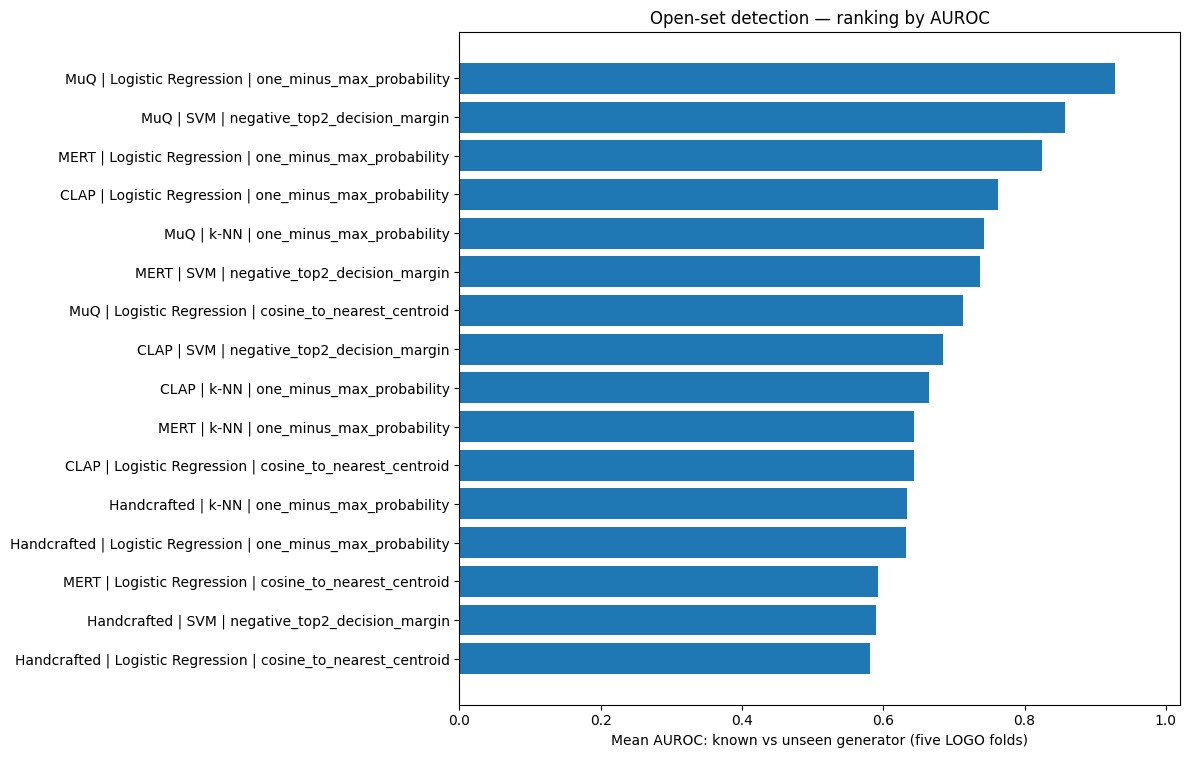

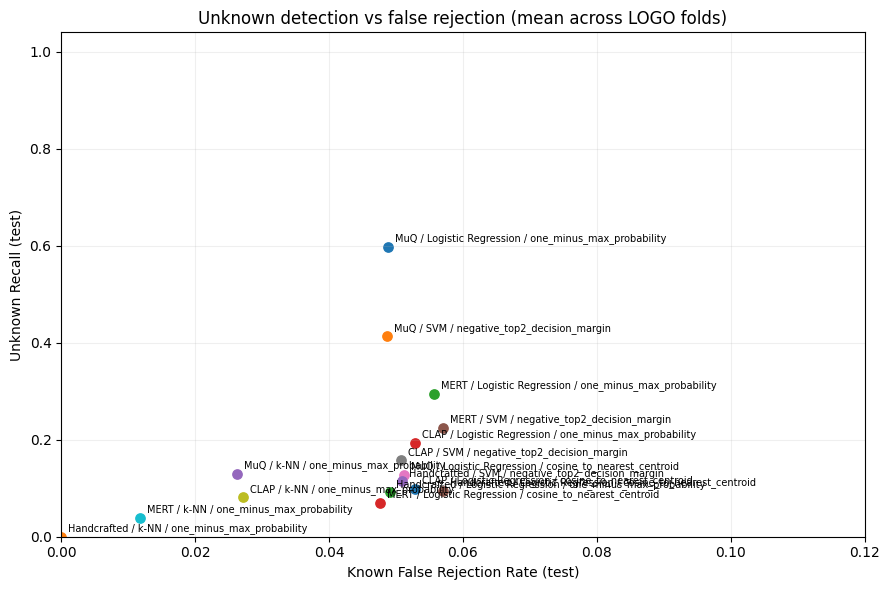

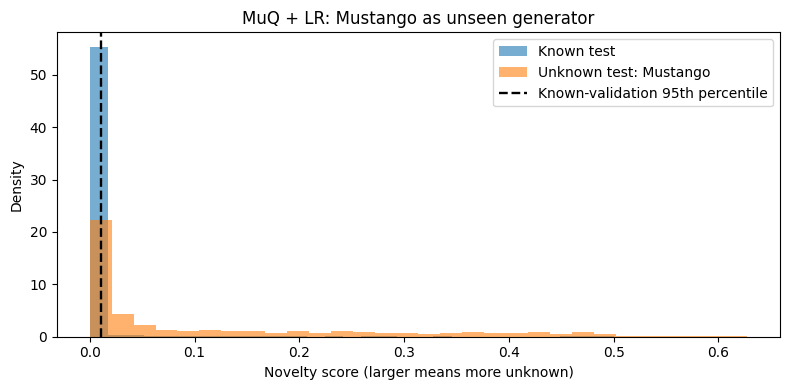

In [37]:
plot_df = comparison.copy()
plot_df['method_label'] = (plot_df['representation'] + ' | ' + plot_df['classifier'] +
                            ' | ' + plot_df['detector'])
fig, ax = plt.subplots(figsize=(12, max(5, 0.48 * len(plot_df))))
ax.barh(plot_df['method_label'], plot_df['auroc_mean'])
ax.invert_yaxis()
ax.set_xlim(0, 1.02)
ax.set_xlabel('Mean AUROC: known vs unseen generator (five LOGO folds)')
ax.set_title('Open-set detection — ranking by AUROC')
fig.tight_layout()
fig.savefig(OUT_DIR / 'comparison_auroc.png', dpi=170)
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
for row in comparison.itertuples(index=False):
    ax.scatter(row.known_frr_mean, row.unknown_recall_mean, s=45)
    ax.annotate(f'{row.representation} / {row.classifier} / {row.detector}',
                (row.known_frr_mean, row.unknown_recall_mean),
                xytext=(5, 4), textcoords='offset points', fontsize=7)
ax.set(xlabel='Known False Rejection Rate (test)', ylabel='Unknown Recall (test)',
       xlim=(0, max(0.12, comparison['known_frr_mean'].max() * 1.12)), ylim=(0, 1.04),
       title='Unknown detection vs false rejection (mean across LOGO folds)')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT_DIR / 'comparison_recall_vs_known_frr.png', dpi=170)
plt.show()

if diagnostic is not None:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(diagnostic['known'], bins=30, alpha=0.6, density=True, label='Known test')
    ax.hist(diagnostic['unknown'], bins=30, alpha=0.6, density=True, label='Unknown test: Mustango')
    ax.axvline(diagnostic['threshold'], color='black', ls='--', lw=1.7,
               label='Known-validation 95th percentile')
    ax.set(xlabel='Novelty score (larger means more unknown)', ylabel='Density',
           title='MuQ + LR: Mustango as unseen generator')
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT_DIR / 'muq_lr_mustango_novelty.png', dpi=170)
    plt.show()

## 8. Save the results

This cell saves all per-fold metrics, per-method averages, optional per-clip test predictions, the parameters of the current run, and visualizations to `results/open_set/unknown_detection/`.

In [38]:
results.to_csv(OUT_DIR / 'unknown_detection_fold_metrics.csv', index=False)
comparison.to_csv(OUT_DIR / 'unknown_detection_method_comparison.csv', index=False)
per_generator.to_csv(OUT_DIR / 'unknown_detection_by_generator.csv', index=False)
if SAVE_ALL_PREDICTIONS and all_prediction_frames:
    all_predictions = pd.concat(all_prediction_frames, ignore_index=True)
    all_predictions.to_csv(OUT_DIR / 'unknown_detection_test_predictions.csv', index=False)
    print('Saved test predictions:', len(all_predictions))
    del all_predictions

run_settings = {
    'run_extended': RUN_EXTENDED,
    'representations': REPRESENTATION_ORDER,
    'classifiers': CLASSIFIERS,
    'target_known_acceptance_validation': TARGET_KNOWN_ACCEPTANCE,
    'random_state': RANDOM_STATE,
    'threshold_selection': '95th percentile of known-validation novelty; strictly greater rejects',
    'unknown_definition': 'one full FakeMusicCaps generator held out per fold',
    'split_policy': 'reuse original track_id-grouped train / validation / test',
    'model_factories': 'src/ai_music_origin/models.py, config/default.yaml',
    'selection_limit': 'exploratory model comparison on 5 LOGO test folds; external confirmatory test needed',
}
(OUT_DIR / 'run_settings.json').write_text(json.dumps(run_settings, indent=2), encoding='utf-8')
for name in ['unknown_detection_fold_metrics.csv', 'unknown_detection_method_comparison.csv',
             'unknown_detection_by_generator.csv', 'run_settings.json']:
    print('Saved', (OUT_DIR / name).relative_to(ROOT))

Saved test predictions: 331600
Saved results\open_set\unknown_detection\unknown_detection_fold_metrics.csv
Saved results\open_set\unknown_detection\unknown_detection_method_comparison.csv
Saved results\open_set\unknown_detection\unknown_detection_by_generator.csv
Saved results\open_set\unknown_detection\run_settings.json
